# 00 | From local tumour to distributed brain networks

**Question:** What did we measure, and what can a paired single case tell us?

Run with the project uv environment. All data, atlas files and computed results are bundled. Real data never fall back to random arrays. Orange/yellow lesion overlays refer to the **preoperative mask**, including when transported to postoperative space.

**Primary FC stability:** notebook 14 recommends 97 distinct frames per session from nonreplacement ten-frame blocks, with complete WM/CSF nuisance refitting. These equal-duration subset ranges are conditional stability summaries, not full-run confidence intervals. The observed full-run points remain unchanged. Notebooks 10/11/13 retain earlier bootstrap, matching and mechanism analyses as sensitivities. See `config/PRIMARY_FC_RESAMPLING.md`. **Current SC policy:** graphs, network means and simulations use each session's 16/20 consensus with mean counts per 10,000 attempted seeds. Primary paired coupling uses the 823-edge intersection with session-specific weights. See `config/PRIMARY_SC.md`. Historical seed-160 diagnostics in notebooks 07/08 remain sensitivity analyses; notebook 09 supplies the reliability evidence. Notebook 10 quantifies joint seed/FC sampling under this policy, including matched designs and support reselection. Notebook 11 extends the full-run branch to paired nuisance refits; notebook 12 integrates all clinical/context fields with network uncertainty. Notebook 13 diagnoses PCA-training shifts and compares nonreplacement blocks at matched distinct counts and 80% retention. The rule is post hoc and does not validate anatomy or a surgical/cognitive effect.

In [1]:
from pathlib import Path
import os, sys, json
root = Path.cwd() if (Path.cwd()/"pyproject.toml").exists() else Path.cwd().parent
os.environ.setdefault("MPLCONFIGDIR", str(root/".cache/matplotlib"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, Markdown, Image
from pat16 import ROOT, DATA, RESULTS, SESSIONS
from pat16.connectivity import labels
from pat16.primary_sc import load_weights
nodes = pd.read_csv(RESULTS/"nodes.csv")
summary = json.loads((RESULTS/"summary.json").read_text())
plt.rcParams.update({"figure.figsize": (9,4), "font.size": 10})


## The evidence chain
T1 anatomy locates the lesion and provides a coordinate system. Diffusion MRI estimates local water-diffusion orientation; tractography builds an anatomical **estimate** of SC. Resting BOLD correlations estimate FC. CANTAB and questionnaires measure selected aspects of experience and performance. None of these is a direct measure of all cognition or quality of life.

The local release has pre-op reference SC/FC, but no paired supplied connectomes or full preprocessing derivatives. Our paired matrices are newly computed using one pipeline. The original reference uses DK68 and must **not** be subtracted from Schaefer100.

The patient is a 39-year-old male with the source diagnosis “Anaplastic astrocytoma II–III.” This historical description is preserved; no modern molecular diagnosis is inferred.

In [2]:
import nibabel as nib
rows=[]
for session in SESSIONS:
    for modality,pattern in [("T1","anat/*T1w.nii.gz"),("DWI AP","dwi/*AP_dwi.nii.gz"),("DWI PA","dwi/*PA_dwi.nii.gz"),("BOLD","func/*bold.nii.gz")]:
        p=next((DATA/f"sub-PAT16/ses-{session}").glob(pattern));im=nib.load(p)
        meta=json.loads(Path(str(p).replace('.nii.gz','.json')).read_text())
        row=dict(session=session,modality=modality,shape=im.shape,zooms=im.header.get_zooms(),orientation=nib.aff2axcodes(im.affine),PE=meta.get('PhaseEncodingDirection'),readout_seconds=meta.get('TotalReadoutTime'))
        if modality.startswith('DWI'):
            bv=np.loadtxt(str(p).replace('.nii.gz','.bval'));values,counts=np.unique(bv,return_counts=True)
            row['bvalue_counts_s_mm2']=dict(zip(values.astype(int),counts))
        rows.append(row)
display(pd.DataFrame(rows))
display(pd.read_csv(DATA/"sub-PAT16/sub-PAT16_sessions.tsv",sep="\t"))

,session,modality,shape,zooms,orientation,PE,readout_seconds,bvalue_counts_s_mm2
0,preop,T1,"(160, 256, 256)","(1.0000021, 1.0, 1.0)","(R, A, S)",i-,NaN,NaN
1,preop,DWI AP,"(96, 96, 60, 102)","(2.5, 2.5, 2.5, 8.7)","(L, A, S)",j-,0.02660,"{0: 6, 700: 16, 1200: 30, 2800: 50}"
2,preop,DWI PA,"(96, 96, 60, 2)","(2.5, 2.5, 2.499997, 8.7)","(L, A, S)",j,0.02660,{0: 2}
3,preop,BOLD,"(64, 64, 42, 180)","(3.0, 3.0, 3.0, 2.4)","(L, A, S)",j-,0.01464,NaN
4,postop,T1,"(160, 256, 256)","(1.0000061, 1.0, 1.0)","(R, A, S)",i-,NaN,NaN
5,postop,DWI AP,"(96, 96, 60, 102)","(2.5, 2.5, 2.5, 8.7)","(L, A, S)",j-,0.02660,"{0: 6, 700: 16, 1200: 30, 2800: 50}"
6,postop,DWI PA,"(96, 96, 60, 2)","(2.5, 2.5, 2.5000057, 8.7)","(L, A, S)",j,0.02660,{0: 2}
7,postop,BOLD,"(64, 64, 42, 180)","(3.0, 3.0, 3.0, 2.4)","(L, A, S)",j-,0.01464,NaN


,session_id,stai,pswq,erq_reappraisal,erq_suppression,erq_processing,erq_expression,loneliness,marital_status,education_level,...,rvp_prob_hit,rvp_false_alarms,rvp_latency_mean,rvp_latency_md,soc_prob_min_moves,soc_mean_moves_2,soc_mean_moves_3,soc_mean_moves_4,soc_mean_moves_5,ssp_span_length
0,ses-preop,36,54,24,17,8,10,40,Cohabiting,3,...,0.810000,0,448.730000,377,8,2,3,5.0,7.75,6
1,ses-postop,30,61,14,19,4,8,50,Cohabiting,3,...,0.814815,1,455.181818,398,8,2,3,6.5,6.25,7


## Coordinate transforms are data
NIfTI voxel indices are not anatomical coordinates. T1 and EPI grids differ in orientation, spacing and field of view. We use SimpleITK fixed-to-moving pull maps in LPS millimetres; plotting uses Nibabel RAS coordinates. A native T1 lesion mask is resampled by its header, not copied by voxel index.

MNI→pre-op atlas projection uses a head-image affine fit followed by brain-only refinement. Post-op labels retain node identity via rigid longitudinal alignment outside the pre-op lesion. Rigid registration does not reconstruct resection-related tissue deformation. The MNI2009 rsHRF maps are **not** combined with the FSL MNI atlas.

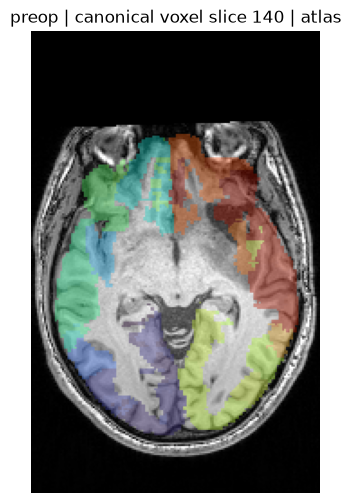

interactive(children=(Dropdown(description='session', options=('preop', 'postop'), value='preop'), IntSlider(v…

<function pat16.views.show_slice(session='preop', z=140, overlay='atlas')>

In [3]:
display(Image(filename=str(RESULTS/"figures/registration_qc.png")))
from pat16.views import show_slice
widgets.interact(show_slice,session=widgets.Dropdown(options=SESSIONS),z=widgets.IntSlider(min=40,max=220,value=140),overlay=widgets.Dropdown(options=["atlas","dwi","func","preop lesion footprint"]))

In [4]:
display(nodes.sort_values("lesion_overlap_fraction",ascending=False)[["label","network","hemisphere","lesion_overlap_fraction","distance_to_lesion_mm"]].head(12))
print("Mask volume (ml):",round(summary["lesion_volume_ml"],2),"; source metadata:",summary["reported_tumor_volume_ml"])
print("Common FC nodes:",summary["common_fc_nodes"])
print(json.dumps(json.loads((RESULTS/"anatomy/complete.json").read_text()),indent=2))

,label,network,hemisphere,lesion_overlap_fraction,distance_to_lesion_mm
75,7Networks_RH_SalVentAttn_FrOperIns_1,SalVentAttn,RH,0.725410,0.0
93,7Networks_RH_Default_PFCv_1,Default,RH,0.508804,0.0
59,7Networks_RH_SomMot_2,SomMot,RH,0.368520,0.0
78,7Networks_RH_Limbic_OFC_1,Limbic,RH,0.313091,0.0
91,7Networks_RH_Default_Temp_2,Default,RH,0.288908,0.0
79,7Networks_RH_Limbic_TempPole_1,Limbic,RH,0.254221,0.0
60,7Networks_RH_SomMot_3,SomMot,RH,0.222448,0.0
58,7Networks_RH_SomMot_1,SomMot,RH,0.187928,0.0
94,7Networks_RH_Default_PFCv_2,Default,RH,0.058452,0.0
92,7Networks_RH_Default_Temp_3,Default,RH,0.038190,0.0


Mask volume (ml): 45.43 ; source metadata: 50.24
Common FC nodes: 100
{
  "mni_rigid": {
    "metric": -0.4471953621837378,
    "stop": "RegularStepGradientDescentOptimizerv4: Step too small after 14 iterations. Current step (0.00195312) is less than minimum step (0.002)."
  },
  "mni_affine": {
    "metric": -0.5929733225297024,
    "stop": "RegularStepGradientDescentOptimizerv4: Step too small after 58 iterations. Current step (0.00195312) is less than minimum step (0.002)."
  },
  "brain_only_affine_refinement": {
    "metric": -0.6570812970638336,
    "stop": "RegularStepGradientDescentOptimizerv4: Step too small after 21 iterations. Current step (0.00195312) is less than minimum step (0.002)."
  },
  "longitudinal_rigid": {
    "metric": -0.9824083740441215,
    "stop": "RegularStepGradientDescentOptimizerv4: Step too small after 15 iterations. Current step (0.00195312) is less than minimum step (0.002)."
  },
  "postop_mask": "transported preop lesion footprint, NOT postoperative

## Exercise: quality before interpretation
Move through inferior, middle and superior slices for each modality. Identify mismatch at cortex, ventricles, lesion and skull base. Are the findings robust to discarding low-coverage parcels? The saved transforms permit external inspection.

**Boundary of evidence:** DWI uses FSL topup susceptibility correction and eddy-current/motion correction with rotated gradients and outlier replacement. BOLD now uses a rigidly transferred static AP/PA field and its own readout time. Slice timing remains uncorrected; unknown shim compatibility, field drift and readout metadata are limitations. No cavity segmentation, postoperative interval, medications, radiotherapy history, normative CANTAB scores or dedicated QoL scale is supplied.

**Provenance:** `uv run python scripts/manifest.py --verify` checks every copied input. Use `uv run python scripts/run_all.py --from-raw --force` to recompute.